In [2]:
!cp "/content/drive/MyDrive/Colab Notebooks/ILLM/bigram_shift.txt" /content/

In [3]:
!cp "/content/drive/MyDrive/Colab Notebooks/ILLM/sentence_length.txt" /content/

In [4]:
!cp "/content/drive/MyDrive/Colab Notebooks/ILLM/subj_number.txt" /content/

In [5]:
# Cell 1: Install required libraries

!pip install -q transformers scikit-learn pandas numpy matplotlib seaborn tqdm

In [6]:
# Cell 2: Import libraries and check the environment

import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

from transformers import AutoTokenizer, AutoModel

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4


In [7]:
# Cell 3: Check files and inspect sample lines

DATA_FILES = {
    "sentence_length": "/content/sentence_length.txt",
    "bigram_shift": "/content/bigram_shift.txt",
    "subj_number": "/content/subj_number.txt"
}

for task, path in DATA_FILES.items():
    print("\n" + "=" * 70)
    print("TASK:", task)
    print("FILE:", path)

    if not os.path.exists(path):
        print("ERROR: File not found!")
        continue

    print("File size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

    with open(path, "r", encoding="utf-8") as f:
        for i in range(5):
            line = f.readline()
            if not line:
                break
            print(f"Line {i + 1}: {repr(line.rstrip())}")


TASK: sentence_length
FILE: /content/sentence_length.txt
File size: 9.5 MB
Line 1: 'tr\t0\tBut it was not here .'
Line 2: 'tr\t0\tThe one no one cared about .'
Line 3: 'tr\t0\tThe Bible would be staying here .'
Line 4: 'tr\t0\tIt \'s a long hike . "'
Line 5: 'tr\t0\tA very bad idea .'

TASK: bigram_shift
FILE: /content/bigram_shift.txt
File size: 8.13 MB
Line 1: "tr\tI\tA week she 'd been with the man , just a week , and she had survived barely the ups and downs ."
Line 2: 'tr\tI\tHe poured out his to heart God , and after a few minutes the need left him , for a while anyway .'
Line 3: "tr\tI\tWe can 't him put at the scene because plenty of people saw him with you at that roadhouse ."
Line 4: 'tr\tO\tI hated even hearing that name now .'
Line 5: 'tr\tI\tThis is my Eve Christmas .'

TASK: subj_number
FILE: /content/subj_number.txt
File size: 8.84 MB
Line 1: 'tr\tNN\tComing from a xenophobic race that possesses the unique ability to pass among other species and chooses not to , the bou

In [8]:
# Cell 4: Load datasets using their actual TSV structure

def load_probing_dataset(path, task_name):
    df = pd.read_csv(
        path,
        sep="\t",
        header=None,
        names=["split", "label", "sentence"],
        quoting=3,
        on_bad_lines="error"
    )

    # Remove invalid or empty sentences
    df = df.dropna(subset=["label", "sentence"])
    df["label"] = df["label"].astype(str).str.strip()
    df["sentence"] = df["sentence"].astype(str).str.strip()

    df = df[df["sentence"].str.len() > 0].reset_index(drop=True)

    print(f"\n{task_name}")
    print("-" * 50)
    print("Total samples:", len(df))
    print("Classes:", sorted(df["label"].unique()))
    print("\nClass distribution:")
    print(df["label"].value_counts().sort_index())
    print("\nSample:")
    print(df.head(3).to_string(index=False))

    return df


datasets = {}

for task, path in DATA_FILES.items():
    datasets[task] = load_probing_dataset(path, task)


sentence_length
--------------------------------------------------
Total samples: 119988
Classes: ['0', '1', '2', '3', '4', '5']

Class distribution:
label
0    19998
1    19998
2    19998
3    19998
4    19998
5    19998
Name: count, dtype: int64

Sample:
split label                          sentence
   tr     0             But it was not here .
   tr     0      The one no one cared about .
   tr     0 The Bible would be staying here .

bigram_shift
--------------------------------------------------
Total samples: 120000
Classes: ['I', 'O']

Class distribution:
label
I    60000
O    60000
Name: count, dtype: int64

Sample:
split label                                                                                          sentence
   tr     I   A week she 'd been with the man , just a week , and she had survived barely the ups and downs .
   tr     I He poured out his to heart God , and after a few minutes the need left him , for a while anyway .
   tr     I      We can 't him put at

In [9]:
# Cell 5: Check whether each dataset supports 50,000 balanced samples

for task, df in datasets.items():
    print(f"\n{task}")
    counts = df["label"].value_counts()

    for label, count in counts.items():
        print(f"Class {label}: {count:,} samples")

    if len(counts) == 2:
        print("Required per class: 25,000")
        print("Can create 50,000 balanced samples:",
              counts.min() >= 25000)
    else:
        print("Number of classes:", len(counts))
        print("Required per class:",
              50000 // len(counts))


sentence_length
Class 0: 19,998 samples
Class 1: 19,998 samples
Class 2: 19,998 samples
Class 3: 19,998 samples
Class 4: 19,998 samples
Class 5: 19,998 samples
Number of classes: 6
Required per class: 8333

bigram_shift
Class I: 60,000 samples
Class O: 60,000 samples
Required per class: 25,000
Can create 50,000 balanced samples: True

subj_number
Class NN: 60,000 samples
Class NNS: 60,000 samples
Required per class: 25,000
Can create 50,000 balanced samples: True


In [10]:
# Cell 6: Balance each dataset to exactly 50,000 samples

TARGET_SIZE = 50000

def create_balanced_dataset(df, task_name, target_size=50000, seed=42):

    classes = sorted(df["label"].unique())
    num_classes = len(classes)

    base_samples = target_size // num_classes
    remainder = target_size % num_classes

    balanced_parts = []

    for i, label in enumerate(classes):

        # Distribute any remaining samples across the first classes
        n_samples = base_samples + (1 if i < remainder else 0)

        class_df = df[df["label"] == label]

        if len(class_df) < n_samples:
            raise ValueError(
                f"Insufficient samples for class {label}: "
                f"available={len(class_df)}, required={n_samples}"
            )

        sampled = class_df.sample(
            n=n_samples,
            replace=False,
            random_state=seed
        )

        balanced_parts.append(sampled)

    balanced_df = pd.concat(
        balanced_parts,
        ignore_index=True
    )

    # Shuffle the complete dataset
    balanced_df = balanced_df.sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    print(f"\n{task_name}")
    print("-" * 50)
    print("Total samples:", len(balanced_df))
    print("Class distribution:")
    print(balanced_df["label"].value_counts().sort_index())

    return balanced_df


balanced_datasets = {}

for task, df in datasets.items():
    balanced_datasets[task] = create_balanced_dataset(
        df,
        task,
        TARGET_SIZE,
        SEED
    )


sentence_length
--------------------------------------------------
Total samples: 50000
Class distribution:
label
0    8334
1    8334
2    8333
3    8333
4    8333
5    8333
Name: count, dtype: int64

bigram_shift
--------------------------------------------------
Total samples: 50000
Class distribution:
label
I    25000
O    25000
Name: count, dtype: int64

subj_number
--------------------------------------------------
Total samples: 50000
Class distribution:
label
NN     25000
NNS    25000
Name: count, dtype: int64


In [11]:
# Cell 7: Stratified 90:10 train-test split

splits = {}

for task, df in balanced_datasets.items():

    train_df, test_df = train_test_split(
        df,
        test_size=0.10,
        random_state=SEED,
        stratify=df["label"]
    )

    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    splits[task] = {
        "train": train_df,
        "test": test_df
    }

    print(f"\n{task}")
    print("=" * 60)

    print("Training samples:", len(train_df))
    print("Testing samples:", len(test_df))

    print("\nTraining class distribution:")
    print(train_df["label"].value_counts().sort_index())

    print("\nTesting class distribution:")
    print(test_df["label"].value_counts().sort_index())


sentence_length
Training samples: 45000
Testing samples: 5000

Training class distribution:
label
0    7500
1    7500
2    7500
3    7500
4    7500
5    7500
Name: count, dtype: int64

Testing class distribution:
label
0    834
1    834
2    833
3    833
4    833
5    833
Name: count, dtype: int64

bigram_shift
Training samples: 45000
Testing samples: 5000

Training class distribution:
label
I    22500
O    22500
Name: count, dtype: int64

Testing class distribution:
label
I    2500
O    2500
Name: count, dtype: int64

subj_number
Training samples: 45000
Testing samples: 5000

Training class distribution:
label
NN     22500
NNS    22500
Name: count, dtype: int64

Testing class distribution:
label
NN     2500
NNS    2500
Name: count, dtype: int64


In [13]:
# Cell 8: Diagnose sentence overlap between train and test

for task, split_data in splits.items():

    train_df = split_data["train"]
    test_df = split_data["test"]

    train_sentences = set(train_df["sentence"])
    test_sentences = set(test_df["sentence"])

    overlap = train_sentences.intersection(test_sentences)

    # Check labels associated with overlapping sentences
    train_overlap = train_df[train_df["sentence"].isin(overlap)]
    test_overlap = test_df[test_df["sentence"].isin(overlap)]

    print(f"\n{task}")
    print("-" * 60)
    print("Training samples:", len(train_df))
    print("Testing samples:", len(test_df))
    print("Unique overlapping sentences:", len(overlap))

    if overlap:
        train_labels = train_overlap.groupby("sentence")["label"].agg(set)
        test_labels = test_overlap.groupby("sentence")["label"].agg(set)

        conflicting = [
            sentence for sentence in overlap
            if train_labels[sentence] != test_labels[sentence]
        ]

        print("Overlapping sentences with conflicting labels:", len(conflicting))

        print("\nExample overlapping sentences:")
        print(train_overlap.head(3)[["label", "sentence"]].to_string(index=False))

    print("Split sizes correct:", len(train_df) == 45000 and len(test_df) == 5000)


sentence_length
------------------------------------------------------------
Training samples: 45000
Testing samples: 5000
Unique overlapping sentences: 40
Overlapping sentences with conflicting labels: 0

Example overlapping sentences:
label              sentence
    0     " Ready to go ? "
    0 Rafe shook his head .
    0      " I 'm serious .
Split sizes correct: True

bigram_shift
------------------------------------------------------------
Training samples: 45000
Testing samples: 5000
Unique overlapping sentences: 18
Overlapping sentences with conflicting labels: 0

Example overlapping sentences:
label             sentence
    I She her shook head .
    O She shook her head .
    O She shook her head .
Split sizes correct: True

subj_number
------------------------------------------------------------
Training samples: 45000
Testing samples: 5000
Unique overlapping sentences: 23
Overlapping sentences with conflicting labels: 0

Example overlapping sentences:
label                

In [14]:
# Cell 9: Deduplicate each original dataset

clean_datasets = {}

for task, df in datasets.items():

    before = len(df)

    # Remove exact duplicate sentences.
    # If duplicates have different labels, retain the first occurrence.
    df_clean = df.drop_duplicates(
        subset=["sentence"],
        keep="first"
    ).reset_index(drop=True)

    clean_datasets[task] = df_clean

    print(f"\n{task}")
    print("Before deduplication:", before)
    print("After deduplication:", len(df_clean))
    print("Removed:", before - len(df_clean))
    print("Class distribution:")
    print(df_clean["label"].value_counts().sort_index())


sentence_length
Before deduplication: 119988
After deduplication: 118904
Removed: 1084
Class distribution:
label
0    19123
1    19926
2    19955
3    19969
4    19962
5    19969
Name: count, dtype: int64

bigram_shift
Before deduplication: 120000
After deduplication: 119631
Removed: 369
Class distribution:
label
I    59874
O    59757
Name: count, dtype: int64

subj_number
Before deduplication: 120000
After deduplication: 119236
Removed: 764
Class distribution:
label
NN     59760
NNS    59476
Name: count, dtype: int64


In [15]:
# Cell 10: Verify unique samples available per class

for task, df in clean_datasets.items():

    print(f"\n{task}")
    print("-" * 50)

    counts = df["label"].value_counts().sort_index()

    required = 50000 // len(counts)

    print("Number of classes:", len(counts))
    print("Required samples per class:", required)
    print(counts)

    if counts.min() < required:
        print("WARNING: Not enough unique samples for 50,000 balanced samples.")
    else:
        print("PASSED: Enough unique samples available.")


sentence_length
--------------------------------------------------
Number of classes: 6
Required samples per class: 8333
label
0    19123
1    19926
2    19955
3    19969
4    19962
5    19969
Name: count, dtype: int64
PASSED: Enough unique samples available.

bigram_shift
--------------------------------------------------
Number of classes: 2
Required samples per class: 25000
label
I    59874
O    59757
Name: count, dtype: int64
PASSED: Enough unique samples available.

subj_number
--------------------------------------------------
Number of classes: 2
Required samples per class: 25000
label
NN     59760
NNS    59476
Name: count, dtype: int64
PASSED: Enough unique samples available.


In [16]:
# Cell 11: Create balanced datasets from deduplicated data

balanced_datasets = {}

for task, df in clean_datasets.items():

    balanced_datasets[task] = create_balanced_dataset(
        df,
        task,
        TARGET_SIZE,
        SEED
    )


sentence_length
--------------------------------------------------
Total samples: 50000
Class distribution:
label
0    8334
1    8334
2    8333
3    8333
4    8333
5    8333
Name: count, dtype: int64

bigram_shift
--------------------------------------------------
Total samples: 50000
Class distribution:
label
I    25000
O    25000
Name: count, dtype: int64

subj_number
--------------------------------------------------
Total samples: 50000
Class distribution:
label
NN     25000
NNS    25000
Name: count, dtype: int64


In [17]:
# Cell 12: Stratified 90:10 train-test split

splits = {}

for task, df in balanced_datasets.items():

    train_df, test_df = train_test_split(
        df,
        test_size=0.10,
        random_state=SEED,
        stratify=df["label"]
    )

    splits[task] = {
        "train": train_df.reset_index(drop=True),
        "test": test_df.reset_index(drop=True)
    }

    print(f"\n{task}")
    print("Training:", len(train_df))
    print("Testing:", len(test_df))

    print("\nTrain distribution:")
    print(train_df["label"].value_counts().sort_index())

    print("\nTest distribution:")
    print(test_df["label"].value_counts().sort_index())


sentence_length
Training: 45000
Testing: 5000

Train distribution:
label
0    7500
1    7500
2    7500
3    7500
4    7500
5    7500
Name: count, dtype: int64

Test distribution:
label
0    834
1    834
2    833
3    833
4    833
5    833
Name: count, dtype: int64

bigram_shift
Training: 45000
Testing: 5000

Train distribution:
label
I    22500
O    22500
Name: count, dtype: int64

Test distribution:
label
I    2500
O    2500
Name: count, dtype: int64

subj_number
Training: 45000
Testing: 5000

Train distribution:
label
NN     22500
NNS    22500
Name: count, dtype: int64

Test distribution:
label
NN     2500
NNS    2500
Name: count, dtype: int64


In [18]:
# Cell 13: Validate sizes, class balance, and sentence overlap

for task, split_data in splits.items():

    train_df = split_data["train"]
    test_df = split_data["test"]

    overlap = set(train_df["sentence"]) & set(test_df["sentence"])

    assert len(train_df) == 45000
    assert len(test_df) == 5000
    assert len(overlap) == 0

    # Verify proportional class balance
    train_dist = train_df["label"].value_counts(normalize=True).sort_index()
    test_dist = test_df["label"].value_counts(normalize=True).sort_index()

    assert np.allclose(train_dist.values, test_dist.values, atol=0.001)

    print(
        f"{task}: PASSED | "
        f"Train={len(train_df)} | "
        f"Test={len(test_df)} | "
        f"Overlap={len(overlap)}"
    )

print("\nAll three datasets are ready for BERT feature extraction.")

sentence_length: PASSED | Train=45000 | Test=5000 | Overlap=0
bigram_shift: PASSED | Train=45000 | Test=5000 | Overlap=0
subj_number: PASSED | Train=45000 | Test=5000 | Overlap=0

All three datasets are ready for BERT feature extraction.


In [19]:
# Cell 14: Load pretrained BERT Base

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModel.from_pretrained(
    MODEL_NAME,
    output_hidden_states=True
)

bert_model = bert_model.to(device)
bert_model.eval()

# Freeze all BERT parameters
for param in bert_model.parameters():
    param.requires_grad = False

NUM_LAYERS = bert_model.config.num_hidden_layers
HIDDEN_SIZE = bert_model.config.hidden_size
MAX_LENGTH = 128
BATCH_SIZE = 32

print("Model:", MODEL_NAME)
print("Architecture:", bert_model.config.model_type)
print("Encoder layers:", NUM_LAYERS)
print("Hidden size:", HIDDEN_SIZE)
print("Maximum sequence length:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE)
print("Device:", device)

print("\nTotal parameters:",
      sum(p.numel() for p in bert_model.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in bert_model.parameters() if p.requires_grad))

assert NUM_LAYERS == 12, "Expected BERT Base with 12 encoder layers."

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: bert-base-uncased
Architecture: bert
Encoder layers: 12
Hidden size: 768
Maximum sequence length: 128
Batch size: 32
Device: cuda

Total parameters: 109482240
Trainable parameters: 0


In [20]:
# Cell 15: Test extraction from all 12 encoder layers

sample_sentences = [
    "The cat is sitting on the mat.",
    "Language models learn contextual representations."
]

inputs = tokenizer(
    sample_sentences,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
    return_special_tokens_mask=True
)

special_tokens_mask = inputs.pop("special_tokens_mask")

inputs = {k: v.to(device) for k, v in inputs.items()}
special_tokens_mask = special_tokens_mask.to(device)

with torch.inference_mode():

    outputs = bert_model(
        **inputs,
        output_hidden_states=True
    )

    hidden_states = outputs.hidden_states

    # Exclude embedding output; retain the 12 encoder layers
    encoder_states = hidden_states[1:]

    # Exclude padding and special tokens from mean pooling
    pooling_mask = (
        inputs["attention_mask"] *
        (1 - special_tokens_mask)
    ).unsqueeze(-1)

    layer_representations = []

    for layer_output in encoder_states:

        mask = pooling_mask.to(layer_output.dtype)

        pooled = (
            (layer_output * mask).sum(dim=1) /
            mask.sum(dim=1).clamp(min=1)
        )

        layer_representations.append(pooled.cpu())

print("Number of encoder layers:", len(layer_representations))

for i, representation in enumerate(layer_representations, start=1):
    print(f"Layer {i}: {tuple(representation.shape)}")

Number of encoder layers: 12
Layer 1: (2, 768)
Layer 2: (2, 768)
Layer 3: (2, 768)
Layer 4: (2, 768)
Layer 5: (2, 768)
Layer 6: (2, 768)
Layer 7: (2, 768)
Layer 8: (2, 768)
Layer 9: (2, 768)
Layer 10: (2, 768)
Layer 11: (2, 768)
Layer 12: (2, 768)


In [21]:
# Cell 16: Extract and save representations from all 12 layers

import gc

FEATURE_DIR = "/content/bert_probing_features"
os.makedirs(FEATURE_DIR, exist_ok=True)


def extract_layer_features(sentences, task_name, split_name):

    num_samples = len(sentences)

    task_dir = os.path.join(FEATURE_DIR, task_name)
    os.makedirs(task_dir, exist_ok=True)

    # Create one memory-mapped file for each encoder layer
    feature_arrays = []

    for layer_idx in range(1, NUM_LAYERS + 1):

        feature_path = os.path.join(
            task_dir,
            f"{split_name}_layer_{layer_idx}.npy"
        )

        feature_array = np.lib.format.open_memmap(
            feature_path,
            mode="w+",
            dtype=np.float32,
            shape=(num_samples, HIDDEN_SIZE)
        )

        feature_arrays.append(feature_array)

    for start in tqdm(
        range(0, num_samples, BATCH_SIZE),
        desc=f"{task_name} - {split_name}"
    ):

        end = min(start + BATCH_SIZE, num_samples)
        batch_sentences = sentences[start:end]

        inputs = tokenizer(
            batch_sentences,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt",
            return_special_tokens_mask=True
        )

        special_mask = inputs.pop("special_tokens_mask")

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        special_mask = special_mask.to(device)

        with torch.inference_mode():

            outputs = bert_model(
                **inputs,
                output_hidden_states=True
            )

            pooling_mask = (
                inputs["attention_mask"] *
                (1 - special_mask)
            ).unsqueeze(-1)

            # Process the 12 encoder layers
            for layer_idx, layer_output in enumerate(
                outputs.hidden_states[1:]
            ):

                mask = pooling_mask.to(layer_output.dtype)

                pooled = (
                    (layer_output * mask).sum(dim=1) /
                    mask.sum(dim=1).clamp(min=1)
                )

                feature_arrays[layer_idx][start:end] = (
                    pooled.float().cpu().numpy()
                )

        del outputs, inputs, special_mask

    # Flush features to disk
    for array in feature_arrays:
        array.flush()

    del feature_arrays
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"Completed: {task_name} | {split_name}")

In [22]:
# Cell 17: Extract train and test representations

for task, split_data in splits.items():

    print("\n" + "=" * 70)
    print("PROCESSING TASK:", task)
    print("=" * 70)

    # Training representations
    train_sentences = split_data["train"]["sentence"].tolist()

    extract_layer_features(
        train_sentences,
        task,
        "train"
    )

    # Testing representations
    test_sentences = split_data["test"]["sentence"].tolist()

    extract_layer_features(
        test_sentences,
        task,
        "test"
    )

print("\nAll BERT layer representations extracted successfully.")# Cell 17: Extract train and test representations

for task, split_data in splits.items():

    print("\n" + "=" * 70)
    print("PROCESSING TASK:", task)
    print("=" * 70)

    # Training representations
    train_sentences = split_data["train"]["sentence"].tolist()

    extract_layer_features(
        train_sentences,
        task,
        "train"
    )

    # Testing representations
    test_sentences = split_data["test"]["sentence"].tolist()

    extract_layer_features(
        test_sentences,
        task,
        "test"
    )

print("\nAll BERT layer representations extracted successfully.")


PROCESSING TASK: sentence_length


sentence_length - train:   0%|          | 0/1407 [00:00<?, ?it/s]

Completed: sentence_length | train


sentence_length - test:   0%|          | 0/157 [00:00<?, ?it/s]

Completed: sentence_length | test

PROCESSING TASK: bigram_shift


bigram_shift - train:   0%|          | 0/1407 [00:00<?, ?it/s]

... (15 outputs left out)

subj_number - train:   0%|          | 0/1407 [00:00<?, ?it/s]

Completed: subj_number | train


subj_number - test:   0%|          | 0/157 [00:00<?, ?it/s]

Completed: subj_number | test

All BERT layer representations extracted successfully.


In [23]:
# Cell 18: Verify feature dimensions and saved files

for task, split_data in splits.items():

    print(f"\n{task}")
    print("-" * 60)

    for layer_idx in range(1, NUM_LAYERS + 1):

        train_path = os.path.join(
            FEATURE_DIR, task,
            f"train_layer_{layer_idx}.npy"
        )

        test_path = os.path.join(
            FEATURE_DIR, task,
            f"test_layer_{layer_idx}.npy"
        )

        X_train = np.load(train_path, mmap_mode="r")
        X_test = np.load(test_path, mmap_mode="r")

        assert X_train.shape == (45000, 768)
        assert X_test.shape == (5000, 768)

        if layer_idx in [1, 6, 12]:
            print(
                f"Layer {layer_idx}: "
                f"Train={X_train.shape}, "
                f"Test={X_test.shape}"
            )

print("\nAll 36 layer-wise feature sets verified.")


sentence_length
------------------------------------------------------------
Layer 1: Train=(45000, 768), Test=(5000, 768)
Layer 6: Train=(45000, 768), Test=(5000, 768)
Layer 12: Train=(45000, 768), Test=(5000, 768)

bigram_shift
------------------------------------------------------------
Layer 1: Train=(45000, 768), Test=(5000, 768)
Layer 6: Train=(45000, 768), Test=(5000, 768)
Layer 12: Train=(45000, 768), Test=(5000, 768)

subj_number
------------------------------------------------------------
Layer 1: Train=(45000, 768), Test=(5000, 768)
Layer 6: Train=(45000, 768), Test=(5000, 768)
Layer 12: Train=(45000, 768), Test=(5000, 768)

All 36 layer-wise feature sets verified.


In [24]:
# Cell 19: Train Logistic Regression on each BERT encoder layer

import time
import gc

results = []
trained_classifiers = {}

# Consistent configuration for all classifiers
LR_CONFIG = {
    "C": 1.0,
    "max_iter": 1000,
    "solver": "lbfgs",
    "random_state": SEED
}

for task, split_data in splits.items():

    print("\n" + "=" * 75)
    print("TASK:", task)
    print("=" * 75)

    y_train = split_data["train"]["label"].values
    y_test = split_data["test"]["label"].values

    trained_classifiers[task] = {}

    for layer_idx in range(1, NUM_LAYERS + 1):

        print(f"\nTraining Layer {layer_idx}/12...")

        # Load saved representations
        train_path = os.path.join(
            FEATURE_DIR, task,
            f"train_layer_{layer_idx}.npy"
        )

        test_path = os.path.join(
            FEATURE_DIR, task,
            f"test_layer_{layer_idx}.npy"
        )

        X_train = np.load(train_path)
        X_test = np.load(test_path)

        # Train classifier
        classifier = LogisticRegression(**LR_CONFIG)

        start_time = time.time()
        classifier.fit(X_train, y_train)
        training_time = time.time() - start_time

        # Test predictions
        predictions = classifier.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)
        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro"
        )

        # Store classifier
        trained_classifiers[task][layer_idx] = classifier

        # Store results
        results.append({
            "Task": task,
            "Layer": layer_idx,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            "Training_Time_Seconds": training_time
        })

        print(
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Training time: {training_time:.2f}s"
        )

        del X_train, X_test, classifier, predictions
        gc.collect()

# Convert results into DataFrame
results_df = pd.DataFrame(results)

results_df.to_csv(
    "/content/bert_probing_results.csv",
    index=False
)

print("\n" + "=" * 75)
print("ALL CLASSIFIERS TRAINED")
print("=" * 75)

print("Total classifiers:", len(results_df))
print("\nResults:")
print(results_df.to_string(index=False))


TASK: sentence_length

Training Layer 1/12...
Accuracy: 0.9604 | Macro F1: 0.9604 | Training time: 129.55s

Training Layer 2/12...
Accuracy: 0.9520 | Macro F1: 0.9520 | Training time: 118.91s

Training Layer 3/12...
Accuracy: 0.9552 | Macro F1: 0.9552 | Training time: 150.53s

Training Layer 4/12...
Accuracy: 0.9498 | Macro F1: 0.9498 | Training time: 157.90s

Training Layer 5/12...
Accuracy: 0.9336 | Macro F1: 0.9336 | Training time: 259.48s

Training Layer 6/12...
Accuracy: 0.9238 | Macro F1: 0.9238 | Training time: 185.93s

Training Layer 7/12...
Accuracy: 0.9116 | Macro F1: 0.9115 | Training time: 201.29s

Training Layer 8/12...
Accuracy: 0.9024 | Macro F1: 0.9023 | Training time: 196.48s

Training Layer 9/12...
Accuracy: 0.8750 | Macro F1: 0.8748 | Training time: 183.51s

Training Layer 10/12...
Accuracy: 0.8466 | Macro F1: 0.8462 | Training time: 203.19s

Training Layer 11/12...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.8268 | Macro F1: 0.8262 | Training time: 274.12s

Training Layer 12/12...
Accuracy: 0.8168 | Macro F1: 0.8159 | Training time: 182.80s

TASK: bigram_shift

Training Layer 1/12...
Accuracy: 0.5590 | Macro F1: 0.5590 | Training time: 12.71s

Training Layer 2/12...
Accuracy: 0.7114 | Macro F1: 0.7114 | Training time: 18.18s

Training Layer 3/12...
Accuracy: 0.8290 | Macro F1: 0.8290 | Training time: 11.57s

Training Layer 4/12...
Accuracy: 0.8640 | Macro F1: 0.8640 | Training time: 20.45s

Training Layer 5/12...
Accuracy: 0.8818 | Macro F1: 0.8818 | Training time: 13.43s

Training Layer 6/12...
Accuracy: 0.8946 | Macro F1: 0.8946 | Training time: 12.28s

Training Layer 7/12...
Accuracy: 0.9066 | Macro F1: 0.9066 | Training time: 7.69s

Training Layer 8/12...
Accuracy: 0.9172 | Macro F1: 0.9172 | Training time: 5.79s

Training Layer 9/12...
Accuracy: 0.9138 | Macro F1: 0.9138 | Training time: 8.68s

Training Layer 10/12...
Accuracy: 0.9052 | Macro F1: 0.9052 | Training time: 5.

In [25]:
# Cell 20: Create a layer-wise comparison table

accuracy_table = results_df.pivot(
    index="Layer",
    columns="Task",
    values="Accuracy"
)

f1_table = results_df.pivot(
    index="Layer",
    columns="Task",
    values="Macro_F1"
)

print("TEST ACCURACY BY BERT LAYER")
display((accuracy_table * 100).round(2))

print("\nMACRO F1 BY BERT LAYER")
display((f1_table * 100).round(2))

TEST ACCURACY BY BERT LAYER


Task,bigram_shift,sentence_length,subj_number
Layer,,,
1,55.90,96.04,84.16
2,71.14,95.20,83.78
3,82.90,95.52,85.68
4,86.40,94.98,86.44
5,88.18,93.36,88.60
6,89.46,92.38,88.50
7,90.66,91.16,88.38
8,91.72,90.24,88.72
9,91.38,87.50,89.08



MACRO F1 BY BERT LAYER


Task,bigram_shift,sentence_length,subj_number
Layer,,,
1,55.90,96.04,84.16
2,71.14,95.20,83.78
3,82.90,95.52,85.68
4,86.40,94.98,86.44
5,88.18,93.36,88.60
6,89.46,92.38,88.50
7,90.66,91.15,88.38
8,91.72,90.23,88.72
9,91.38,87.48,89.08


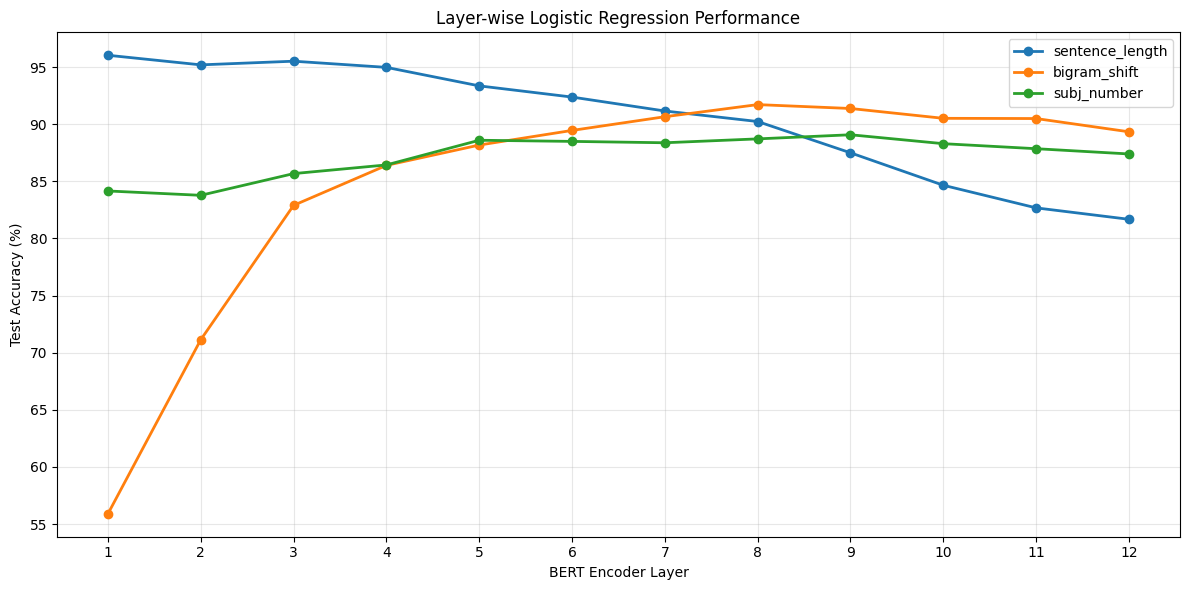

In [26]:
# Cell 21: Plot test accuracy across the 12 BERT layers

plt.figure(figsize=(12, 6))

for task in results_df["Task"].unique():

    task_results = results_df[results_df["Task"] == task]

    plt.plot(
        task_results["Layer"],
        task_results["Accuracy"] * 100,
        marker="o",
        linewidth=2,
        label=task
    )

plt.xticks(range(1, 13))
plt.xlabel("BERT Encoder Layer")
plt.ylabel("Test Accuracy (%)")
plt.title("Layer-wise Logistic Regression Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Cell 22: Find the best-performing layer for each task

best_layers = (
    results_df.loc[
        results_df.groupby("Task")["Accuracy"].idxmax()
    ]
    .sort_values("Task")
    .reset_index(drop=True)
)

print("BEST BERT LAYER FOR EACH TASK")
display(
    best_layers[
        ["Task", "Layer", "Accuracy", "Macro_F1", "Training_Time_Seconds"]
    ].round(4)
)

BEST BERT LAYER FOR EACH TASK


,Task,Layer,Accuracy,Macro_F1,Training_Time_Seconds
0,bigram_shift,8,0.9172,0.9172,5.7904
1,sentence_length,1,0.9604,0.9604,129.5461
2,subj_number,9,0.8908,0.8908,9.3079



TASK: bigram_shift | BEST LAYER: 8
              precision    recall  f1-score   support

           I       0.93      0.90      0.92      2500
           O       0.91      0.93      0.92      2500

    accuracy                           0.92      5000
   macro avg       0.92      0.92      0.92      5000
weighted avg       0.92      0.92      0.92      5000



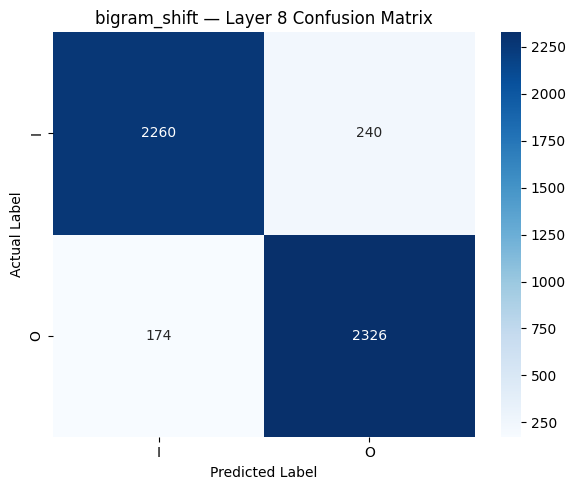


TASK: sentence_length | BEST LAYER: 1
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       834
           1       0.97      0.97      0.97       834
           2       0.96      0.95      0.95       833
           3       0.94      0.95      0.94       833
           4       0.95      0.93      0.94       833
           5       0.96      0.98      0.97       833

    accuracy                           0.96      5000
   macro avg       0.96      0.96      0.96      5000
weighted avg       0.96      0.96      0.96      5000



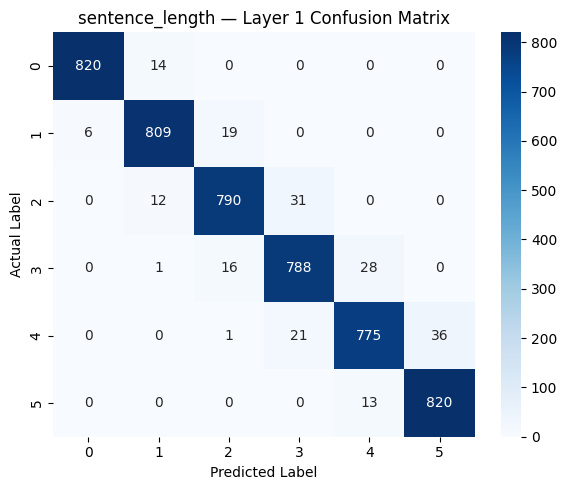


TASK: subj_number | BEST LAYER: 9
              precision    recall  f1-score   support

          NN       0.89      0.90      0.89      2500
         NNS       0.90      0.88      0.89      2500

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000



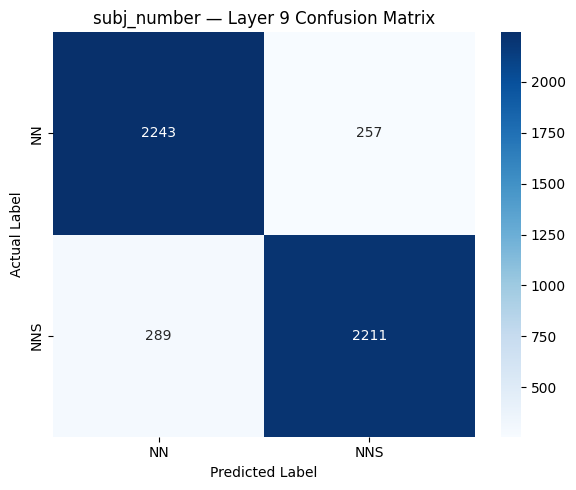

In [28]:
# Cell 23: Detailed classification reports for best layers

from sklearn.metrics import classification_report, confusion_matrix

best_layer_reports = {}

for _, row in best_layers.iterrows():

    task = row["Task"]
    layer = int(row["Layer"])

    print("\n" + "=" * 75)
    print(f"TASK: {task} | BEST LAYER: {layer}")
    print("=" * 75)

    # Load test representations
    X_test = np.load(
        os.path.join(
            FEATURE_DIR,
            task,
            f"test_layer_{layer}.npy"
        )
    )

    y_test = splits[task]["test"]["label"].values

    # Retrieve trained classifier
    classifier = trained_classifiers[task][layer]

    predictions = classifier.predict(X_test)

    # Classification report
    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    best_layer_reports[task] = report

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    # Confusion matrix
    labels = classifier.classes_

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"{task} — Layer {layer} Confusion Matrix")
    plt.tight_layout()
    plt.show()

    del X_test

In [29]:
# Cell 24: Compare our BERT results with published probing baselines

paper_results = pd.DataFrame([
    {
        "Task": "sentence_length",
        "Majority_Baseline": 20.0,
        "FastText_BoV": 66.6,
        "Strong_Encoder_Reference": 94.0
    },
    {
        "Task": "bigram_shift",
        "Majority_Baseline": 50.0,
        "FastText_BoV": 50.8,
        "Strong_Encoder_Reference": 80.9
    },
    {
        "Task": "subj_number",
        "Majority_Baseline": 50.0,
        "FastText_BoV": 82.1,
        "Strong_Encoder_Reference": 91.5
    }
])

# Get the best BERT accuracy for each task
bert_comparison = (
    best_layers[["Task", "Layer", "Accuracy", "Macro_F1"]]
    .copy()
)

bert_comparison["BERT_Accuracy_Percent"] = (
    bert_comparison["Accuracy"] * 100
)

# Merge our results with published reference values
comparison_df = bert_comparison.merge(
    paper_results,
    on="Task"
)

comparison_df["Difference_vs_FastText"] = (
    comparison_df["BERT_Accuracy_Percent"] -
    comparison_df["FastText_BoV"]
)

comparison_df["Difference_vs_Strong_Encoder"] = (
    comparison_df["BERT_Accuracy_Percent"] -
    comparison_df["Strong_Encoder_Reference"]
)

comparison_df = comparison_df.rename(columns={
    "Accuracy": "BERT_Accuracy",
    "Macro_F1": "BERT_Macro_F1"
})

print("BERT VS PUBLISHED PROBING RESULTS")
display(
    comparison_df.round(2)
)

comparison_df.to_csv(
    "/content/paper_comparison.csv",
    index=False
)

BERT VS PUBLISHED PROBING RESULTS


,Task,Layer,BERT_Accuracy,BERT_Macro_F1,BERT_Accuracy_Percent,Majority_Baseline,FastText_BoV,Strong_Encoder_Reference,Difference_vs_FastText,Difference_vs_Strong_Encoder
0,bigram_shift,8,0.92,0.92,91.72,50.0,50.8,80.9,40.92,10.82
1,sentence_length,1,0.96,0.96,96.04,20.0,66.6,94.0,29.44,2.04
2,subj_number,9,0.89,0.89,89.08,50.0,82.1,91.5,6.98,-2.42


In [30]:
# Cell 25: Generate task-wise observations

observations = []

for task in results_df["Task"].unique():

    task_df = results_df[
        results_df["Task"] == task
    ].sort_values("Layer")

    best = task_df.loc[task_df["Accuracy"].idxmax()]
    worst = task_df.loc[task_df["Accuracy"].idxmin()]

    first_layer = task_df.iloc[0]
    last_layer = task_df.iloc[-1]

    observation = {
        "Task": task,
        "Best_Layer": int(best["Layer"]),
        "Best_Accuracy": best["Accuracy"] * 100,
        "Best_Macro_F1": best["Macro_F1"] * 100,
        "Worst_Layer": int(worst["Layer"]),
        "Worst_Accuracy": worst["Accuracy"] * 100,
        "Layer_1_Accuracy": first_layer["Accuracy"] * 100,
        "Layer_12_Accuracy": last_layer["Accuracy"] * 100,
        "Layer_1_to_12_Change": (
            last_layer["Accuracy"] - first_layer["Accuracy"]
        ) * 100
    }

    observations.append(observation)

    print("\n" + "=" * 65)
    print("TASK:", task)
    print("=" * 65)

    print(
        f"Best layer: {int(best['Layer'])} "
        f"({best['Accuracy'] * 100:.2f}% accuracy)"
    )

    print(
        f"Worst layer: {int(worst['Layer'])} "
        f"({worst['Accuracy'] * 100:.2f}% accuracy)"
    )

    print(
        f"Layer 1 accuracy: {first_layer['Accuracy'] * 100:.2f}%"
    )

    print(
        f"Layer 12 accuracy: {last_layer['Accuracy'] * 100:.2f}%"
    )

    print(
        f"Change from Layer 1 to Layer 12: "
        f"{observation['Layer_1_to_12_Change']:+.2f} percentage points"
    )

observations_df = pd.DataFrame(observations)

observations_df.to_csv(
    "/content/task_observations.csv",
    index=False
)

display(observations_df.round(2))


TASK: sentence_length
Best layer: 1 (96.04% accuracy)
Worst layer: 12 (81.68% accuracy)
Layer 1 accuracy: 96.04%
Layer 12 accuracy: 81.68%
Change from Layer 1 to Layer 12: -14.36 percentage points

TASK: bigram_shift
Best layer: 8 (91.72% accuracy)
Worst layer: 1 (55.90% accuracy)
Layer 1 accuracy: 55.90%
Layer 12 accuracy: 89.34%
Change from Layer 1 to Layer 12: +33.44 percentage points

TASK: subj_number
Best layer: 9 (89.08% accuracy)
Worst layer: 2 (83.78% accuracy)
Layer 1 accuracy: 84.16%
Layer 12 accuracy: 87.40%
Change from Layer 1 to Layer 12: +3.24 percentage points


,Task,Best_Layer,Best_Accuracy,Best_Macro_F1,Worst_Layer,Worst_Accuracy,Layer_1_Accuracy,Layer_12_Accuracy,Layer_1_to_12_Change
0,sentence_length,1,96.04,96.04,12,81.68,96.04,81.68,-14.36
1,bigram_shift,8,91.72,91.72,1,55.90,55.90,89.34,33.44
2,subj_number,9,89.08,89.08,2,83.78,84.16,87.40,3.24


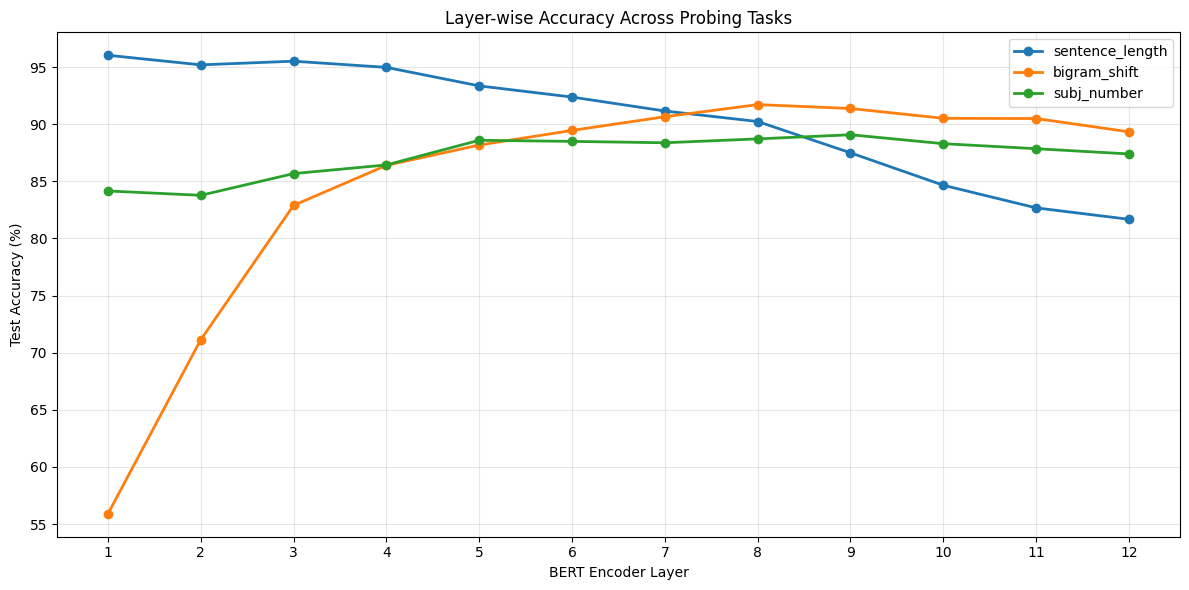

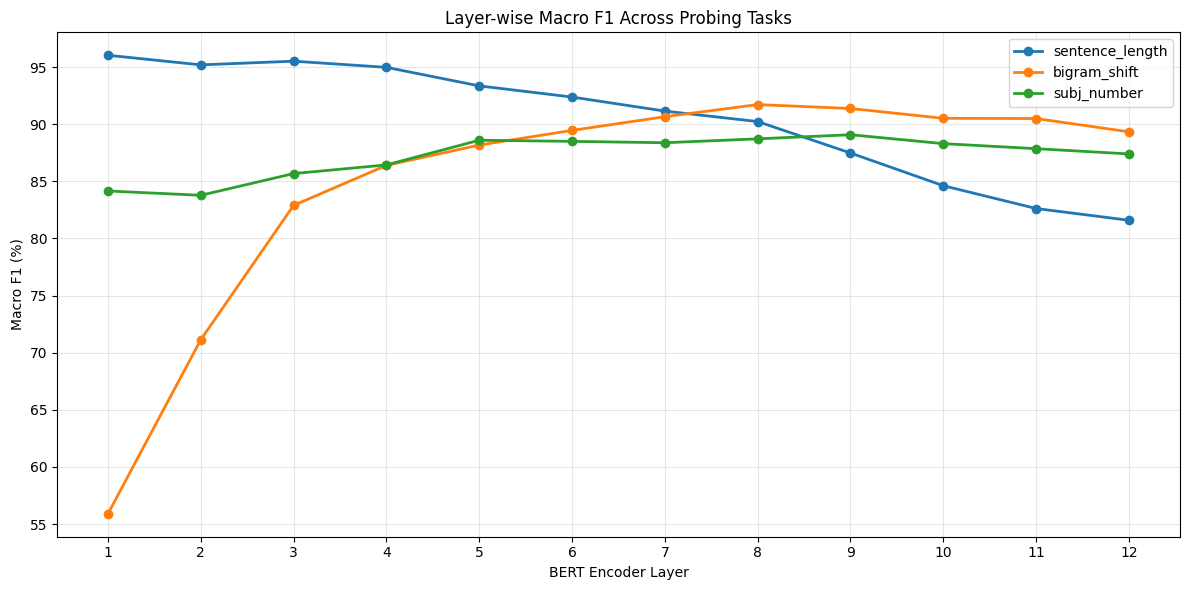

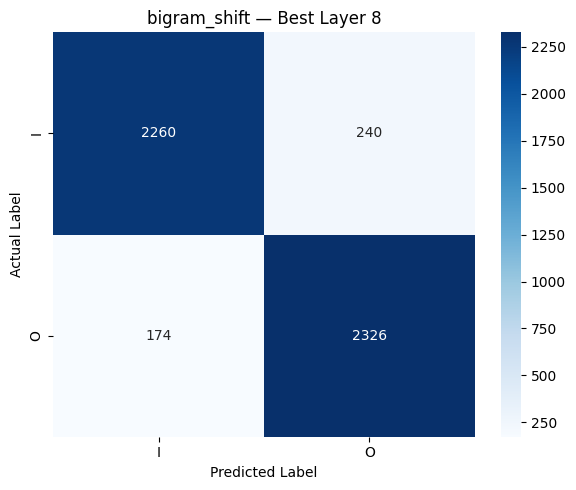

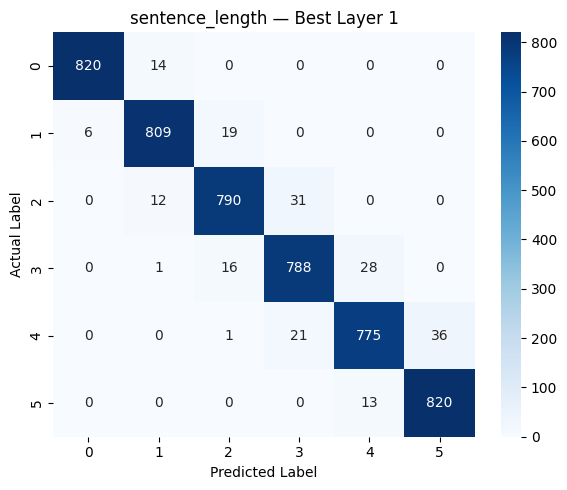

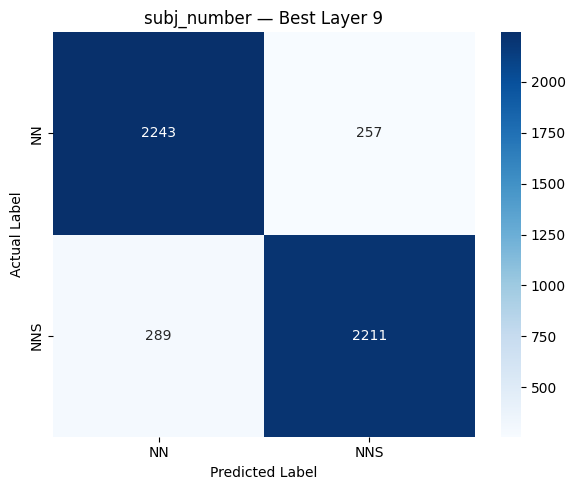

All plots saved in: /content/probing_plots


In [31]:
# Cell 26: Generate and save final plots

PLOT_DIR = "/content/probing_plots"
os.makedirs(PLOT_DIR, exist_ok=True)

# 1. Layer-wise accuracy
plt.figure(figsize=(12, 6))

for task in results_df["Task"].unique():

    task_df = results_df[results_df["Task"] == task]

    plt.plot(
        task_df["Layer"],
        task_df["Accuracy"] * 100,
        marker="o",
        linewidth=2,
        label=task
    )

plt.xticks(range(1, 13))
plt.xlabel("BERT Encoder Layer")
plt.ylabel("Test Accuracy (%)")
plt.title("Layer-wise Accuracy Across Probing Tasks")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "layerwise_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Layer-wise macro F1
plt.figure(figsize=(12, 6))

for task in results_df["Task"].unique():

    task_df = results_df[results_df["Task"] == task]

    plt.plot(
        task_df["Layer"],
        task_df["Macro_F1"] * 100,
        marker="o",
        linewidth=2,
        label=task
    )

plt.xticks(range(1, 13))
plt.xlabel("BERT Encoder Layer")
plt.ylabel("Macro F1 (%)")
plt.title("Layer-wise Macro F1 Across Probing Tasks")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "layerwise_macro_f1.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. Confusion matrices for the best layers
for _, row in best_layers.iterrows():

    task = row["Task"]
    layer = int(row["Layer"])

    X_test = np.load(
        os.path.join(
            FEATURE_DIR,
            task,
            f"test_layer_{layer}.npy"
        )
    )

    y_test = splits[task]["test"]["label"].values
    classifier = trained_classifiers[task][layer]

    predictions = classifier.predict(X_test)
    labels = classifier.classes_

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"{task} — Best Layer {layer}")
    plt.tight_layout()

    filename = f"{task}_confusion_matrix.png"

    plt.savefig(
        os.path.join(PLOT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    del X_test

print("All plots saved in:", PLOT_DIR)

In [32]:
# Cell 27: Export final assignment results

import json
import shutil

OUTPUT_DIR = "/content/Probing_Assignment_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save result tables
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "all_layer_results.csv"),
    index=False
)

best_layers.to_csv(
    os.path.join(OUTPUT_DIR, "best_layers.csv"),
    index=False
)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "paper_comparison.csv"),
    index=False
)

observations_df.to_csv(
    os.path.join(OUTPUT_DIR, "task_observations.csv"),
    index=False
)

# Save classification reports
with open(
    os.path.join(OUTPUT_DIR, "classification_reports.json"),
    "w"
) as f:
    json.dump(best_layer_reports, f, indent=4)

# Copy plots
shutil.copytree(
    PLOT_DIR,
    os.path.join(OUTPUT_DIR, "plots"),
    dirs_exist_ok=True
)

# Save dataset split information
split_summary = {}

for task, split_data in splits.items():

    split_summary[task] = {
        "training_samples": len(split_data["train"]),
        "testing_samples": len(split_data["test"]),
        "training_distribution": {
            str(k): int(v)
            for k, v in split_data["train"]["label"].value_counts().items()
        },
        "testing_distribution": {
            str(k): int(v)
            for k, v in split_data["test"]["label"].value_counts().items()
        }
    }

with open(
    os.path.join(OUTPUT_DIR, "dataset_summary.json"),
    "w"
) as f:
    json.dump(split_summary, f, indent=4)

# Create ZIP archive
ZIP_PATH = shutil.make_archive(
    "/content/Probing_Assignment_Results",
    "zip",
    OUTPUT_DIR
)

print("Export completed successfully.")
print("Output folder:", OUTPUT_DIR)
print("ZIP archive:", ZIP_PATH)
print("\nFiles included:")

for root, dirs, files in os.walk(OUTPUT_DIR):
    for filename in files:
        print(os.path.relpath(
            os.path.join(root, filename),
            OUTPUT_DIR
        ))

print(
    "\nZIP size:",
    round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2),
    "MB"
)

Export completed successfully.
Output folder: /content/Probing_Assignment_Results
ZIP archive: /content/Probing_Assignment_Results.zip

Files included:
dataset_summary.json
all_layer_results.csv
best_layers.csv
paper_comparison.csv
classification_reports.json
task_observations.csv
plots/layerwise_accuracy.png
plots/layerwise_macro_f1.png
plots/sentence_length_confusion_matrix.png
plots/bigram_shift_confusion_matrix.png
plots/subj_number_confusion_matrix.png

ZIP size: 0.56 MB


In [33]:
# Cell 28: Generate a data-driven assignment conclusion

conclusion_lines = []

conclusion_lines.append(
    "# Layer-wise BERT Probing: Experimental Observations and Conclusion\n"
)

conclusion_lines.append("## Experimental Setup\n")

conclusion_lines.append(
    "- Pretrained model: bert-base-uncased\n"
    "- BERT architecture: 12 encoder layers\n"
    "- Sentence representation: Mean pooling over non-padding, "
    "non-special tokens\n"
    "- Classifier: Logistic Regression (C=1.0, lbfgs)\n"
    "- BERT parameters: Frozen during probing\n"
    "- Samples: 50,000 per task\n"
    "- Training set: 45,000 samples (90%)\n"
    "- Test set: 5,000 samples (10%)\n"
)

conclusion_lines.append("\n## Results\n")

for _, row in best_layers.iterrows():

    task = row["Task"]
    layer = int(row["Layer"])

    conclusion_lines.append(
        f"- **{task}:** Best layer = {layer}, "
        f"accuracy = {row['Accuracy'] * 100:.2f}%, "
        f"macro F1 = {row['Macro_F1'] * 100:.2f}%.\n"
    )

conclusion_lines.append("\n## Layer-wise Observations\n")

for _, row in observations_df.iterrows():

    conclusion_lines.append(
        f"- **{row['Task']}:** Performance ranged from "
        f"{row['Worst_Accuracy']:.2f}% at layer "
        f"{int(row['Worst_Layer'])} to "
        f"{row['Best_Accuracy']:.2f}% at layer "
        f"{int(row['Best_Layer'])}. "
        f"Layer 1 to layer 12 accuracy change: "
        f"{row['Layer_1_to_12_Change']:+.2f} percentage points.\n"
    )

conclusion_lines.append("\n## Comparison with Published Results\n")

for _, row in comparison_df.iterrows():

    conclusion_lines.append(
        f"- **{row['Task']}:** BERT best-layer accuracy = "
        f"{row['BERT_Accuracy_Percent']:.2f}%; "
        f"published FastText bag-of-vectors reference = "
        f"{row['FastText_BoV']:.2f}%; "
        f"difference = {row['Difference_vs_FastText']:+.2f} "
        f"percentage points.\n"
    )

conclusion_lines.append(
    "\nThe published results are reference points rather than "
    "directly controlled comparisons because the encoder, "
    "representation method, dataset size, and experimental "
    "configuration differ.\n"
)

conclusion_lines.append("\n## Conclusion\n")

conclusion_lines.append(
    "This experiment investigated the linguistic information "
    "encoded in different layers of a pretrained BERT-base model "
    "using three sentence-level probing tasks: sentence length, "
    "bigram shift, and subject number. BERT was kept frozen, and "
    "a separate Logistic Regression classifier was trained on "
    "the mean-pooled representation from each of its 12 encoder layers. "
    "The best-performing layer varied by task, demonstrating that "
    "different layers provide representations with different "
    "accessibility to the probed linguistic properties. The results "
    "also show how layer-wise probing can be used to examine surface, "
    "syntactic, and grammatical information in contextual sentence "
    "representations. The experiment provides an empirical comparison "
    "with published probing baselines, subject to differences in "
    "experimental settings.\n"
)

conclusion_text = "\n".join(conclusion_lines)

conclusion_path = os.path.join(
    OUTPUT_DIR,
    "observations_and_conclusion.md"
)

with open(conclusion_path, "w", encoding="utf-8") as f:
    f.write(conclusion_text)

print(conclusion_text)
print("\nConclusion saved to:", conclusion_path)

# Rebuild ZIP to include the conclusion
ZIP_PATH = shutil.make_archive(
    "/content/Probing_Assignment_Results",
    "zip",
    OUTPUT_DIR
)

print("\nUpdated ZIP:", ZIP_PATH)

# Layer-wise BERT Probing: Experimental Observations and Conclusion

## Experimental Setup

- Pretrained model: bert-base-uncased
- BERT architecture: 12 encoder layers
- Sentence representation: Mean pooling over non-padding, non-special tokens
- Classifier: Logistic Regression (C=1.0, lbfgs)
- BERT parameters: Frozen during probing
- Samples: 50,000 per task
- Training set: 45,000 samples (90%)
- Test set: 5,000 samples (10%)


## Results

- **bigram_shift:** Best layer = 8, accuracy = 91.72%, macro F1 = 91.72%.

- **sentence_length:** Best layer = 1, accuracy = 96.04%, macro F1 = 96.04%.

- **subj_number:** Best layer = 9, accuracy = 89.08%, macro F1 = 89.08%.


## Layer-wise Observations

- **sentence_length:** Performance ranged from 81.68% at layer 12 to 96.04% at layer 1. Layer 1 to layer 12 accuracy change: -14.36 percentage points.

- **bigram_shift:** Performance ranged from 55.90% at layer 1 to 91.72% at layer 8. Layer 1 to layer 12 accuracy change: +33.44 percentage points.

In [34]:
# Cell 29: Copy final results ZIP to Google Drive

import os
import shutil
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Destination folder
DRIVE_FOLDER = "/content/drive/MyDrive/Colab Notebooks/ILLM"

# Create folder if it doesn't exist
os.makedirs(DRIVE_FOLDER, exist_ok=True)

# Source ZIP
SOURCE_ZIP = "/content/Probing_Assignment_Results.zip"

# Destination ZIP
DESTINATION_ZIP = os.path.join(
    DRIVE_FOLDER,
    "Probing_Assignment_Results.zip"
)

# Copy ZIP to Google Drive
shutil.copy2(SOURCE_ZIP, DESTINATION_ZIP)

print("Successfully saved results to Google Drive!")
print("Location:", DESTINATION_ZIP)
print(
    "File size:",
    round(os.path.getsize(DESTINATION_ZIP) / (1024 * 1024), 2),
    "MB"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully saved results to Google Drive!
Location: /content/drive/MyDrive/Colab Notebooks/ILLM/Probing_Assignment_Results.zip
File size: 0.56 MB
